In [1]:
import pandas as pd
import json

path_to_jstor = '/Users/merlin/Desktop/BA/Bachelorabeit Uni Leipzig/programming/dhox/data/jstor_w_category.json'
path_to_iarchive = '/Users/merlin/Desktop/BA/Bachelorabeit Uni Leipzig/programming/iArchive/iarchive_data.json' 
path_to_scriptorg = '/Users/merlin/Desktop/BA/Bachelorabeit Uni Leipzig/programming/scirp/scrapscript_w_category.json' 

In [2]:
with open(path_to_jstor, encoding='utf-8') as f:
    df_jstor = pd.read_json(f, lines=True)
df_jstor.columns

Index(['index', 'category', 'creator', 'datePublished', 'docSubType',
       'docType', 'doi', 'fullText', 'id', 'identifier', 'isPartOf',
       'issueNumber', 'keyphrase', 'language', 'outputFormat', 'pageCount',
       'pageEnd', 'pageStart', 'pagination', 'provider', 'publicationYear',
       'publisher', 'sequence', 'tdmCategory', 'title', 'url', 'volumeNumber',
       'wordCount', 'unigramCount', 'bigramCount', 'trigramCount',
       'sourceCategory', 'abstract', 'id_count'],
      dtype='object')

In [3]:
df_jstor_cat_date = df_jstor[["category", "datePublished"]]
df_jstor=None

In [4]:
len(df_jstor_cat_date)

20652

In [ ]:
df_jstor_cat_date['datePublished'] = pd.to_datetime(df_jstor_cat_date['datePublished'], format='%Y')
#df_jstor_cat_date['datePublished'] = df_jstor_cat_date['datePublished'].dt.year
df_jstor_cat_date=df_jstor_cat_date.rename(columns={'datePublished':'year'})

df_jstor_cat_date

,category,year
0,archeology,2020-11-09
1,archeology,2012-06-13
2,archeology,2020-06-29
3,archeology,2016-09-14
4,archeology,2015-01-01
...,...,...
20647,ethnology,2020-02-01
20648,ethnology,2021-04-01
20649,ethnology,2022-04-01
20650,ethnology,2022-01-01


In [20]:
with open(path_to_scriptorg, encoding='utf-8') as f:
    df_scriptorg = pd.read_json(f, lines=True)
df_scriptorg.columns

Index(['keywords', 'category', 'href', 'title', 'authors', 'journal', 'issue',
       'date', 'doi', 'abstract', 'fullText', 'doi_count', 'year',
       'keywords_x', 'keywords_y'],
      dtype='object')

In [21]:
df_scriptorg_cat_date = df_scriptorg[['category','year']]
df_scriptorg_cat_date['year'] = pd.to_datetime(df_scriptorg_cat_date['year'], format='%Y')
#df_scriptorg_cat_date['year'] = df_scriptorg_cat_date['year'].dt.year
df_scriptorg = None
df_scriptorg_cat_date

/var/folders/jb/jz3xgqts0zx_lxl_9ylrxrv80000gn/T/ipykernel_54941/2648213849.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_scriptorg_cat_date['year'] = pd.to_datetime(df_scriptorg_cat_date['year'], format='%Y')


,category,year
0,ethnology,2023-01-01
1,ethnology,2023-01-01
2,ethnology,2023-01-01
3,ethnology,2023-01-01
4,ethnology,2023-01-01
...,...,...
36247,archeology,2014-01-01
36248,archeology,2014-01-01
36249,archeology,2014-01-01
36250,archeology,2014-01-01


In [9]:
df_scriptorg_cat_date=df_scriptorg_cat_date.head(19125)
len(df_scriptorg_cat_date)

19125

In [59]:
with open(path_to_iarchive, encoding='utf-8') as f:
    df_iarchive = pd.read_json(f, lines=True)
df_iarchive.columns

Index(['filename', 'content', 'extracted_year'], dtype='object')

In [60]:
df_iarchive_cat_year = df_iarchive[['extracted_year']]
df_iarchive_cat_year = df_iarchive_cat_year.rename(columns={'extracted_year':'year'})
df_iarchive_cat_year['category'] = 'anthropology'
df_iarchive_cat_year['year'] = pd.to_datetime(df_iarchive_cat_year['year'], format='%Y')
#df_iarchive_cat_year['year'] = df_iarchive_cat_year['year'].dt.year
df_iarchive = None

In [61]:
df_iarchive_cat_year

,year,category
0,1960-01-01,anthropology
1,1902-01-01,anthropology
2,1914-01-01,anthropology
3,1895-01-01,anthropology
4,1922-01-01,anthropology
...,...,...
336,1918-01-01,anthropology
337,1899-01-01,anthropology
338,1946-01-01,anthropology
339,1928-01-01,anthropology


In [ ]:
# note that the number of datapoints represents whole Issues published with an approximated number of 14 articles per issue
# this is why the number of datapoints is multiplied by concatenating the df with itself
df_iarchive_cat_year_for_concat = pd.DataFrame(df_iarchive_cat_year)
df_iarchive_cat_year_enhanced = pd.DataFrame()
for i in range(1,14):
    df_iarchive_cat_year_enhanced = pd.concat([df_iarchive_cat_year_for_concat,df_iarchive_cat_year_enhanced], ignore_index=True)
df_iarchive_cat_year_enhanced

,year,category
0,1960-01-01,anthropology
1,1902-01-01,anthropology
2,1914-01-01,anthropology
3,1895-01-01,anthropology
4,1922-01-01,anthropology
...,...,...
4428,1918-01-01,anthropology
4429,1899-01-01,anthropology
4430,1946-01-01,anthropology
4431,1928-01-01,anthropology


In [74]:
all_data_df = pd.concat([df_jstor_cat_date,df_scriptorg_cat_date,df_iarchive_cat_year_enhanced],ignore_index=True)
all_data_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61337 entries, 0 to 61336
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   category  61337 non-null  object        
 1   year      61337 non-null  datetime64[ns]
dtypes: datetime64[ns](1), object(1)
memory usage: 958.5+ KB


In [75]:
data_visualise_cat = all_data_df.groupby('category').size().reset_index(name='count')
data_visualise_cat=data_visualise_cat.sort_values('count', ascending=False)
data_visualise_cat

,category,count
8,ethnology,17073
13,medical sociology,8047
0,anthropology,6835
7,education,5974
1,archeology,4200
5,communication studies,3795
4,climate economics,3332
3,behavioral science,2091
9,feminist studies,1617
14,psychology,1409


In [76]:
data_visualise_cat['category'].to_list()

['ethnology',
 'medical sociology',
 'anthropology',
 'education',
 'archeology',
 'communication studies',
 'climate economics',
 'behavioral science',
 'feminist studies',
 'psychology',
 'urban studies',
 'economics',
 'literature studies',
 'artificial intelligence',
 'law',
 'sociology',
 'information science']

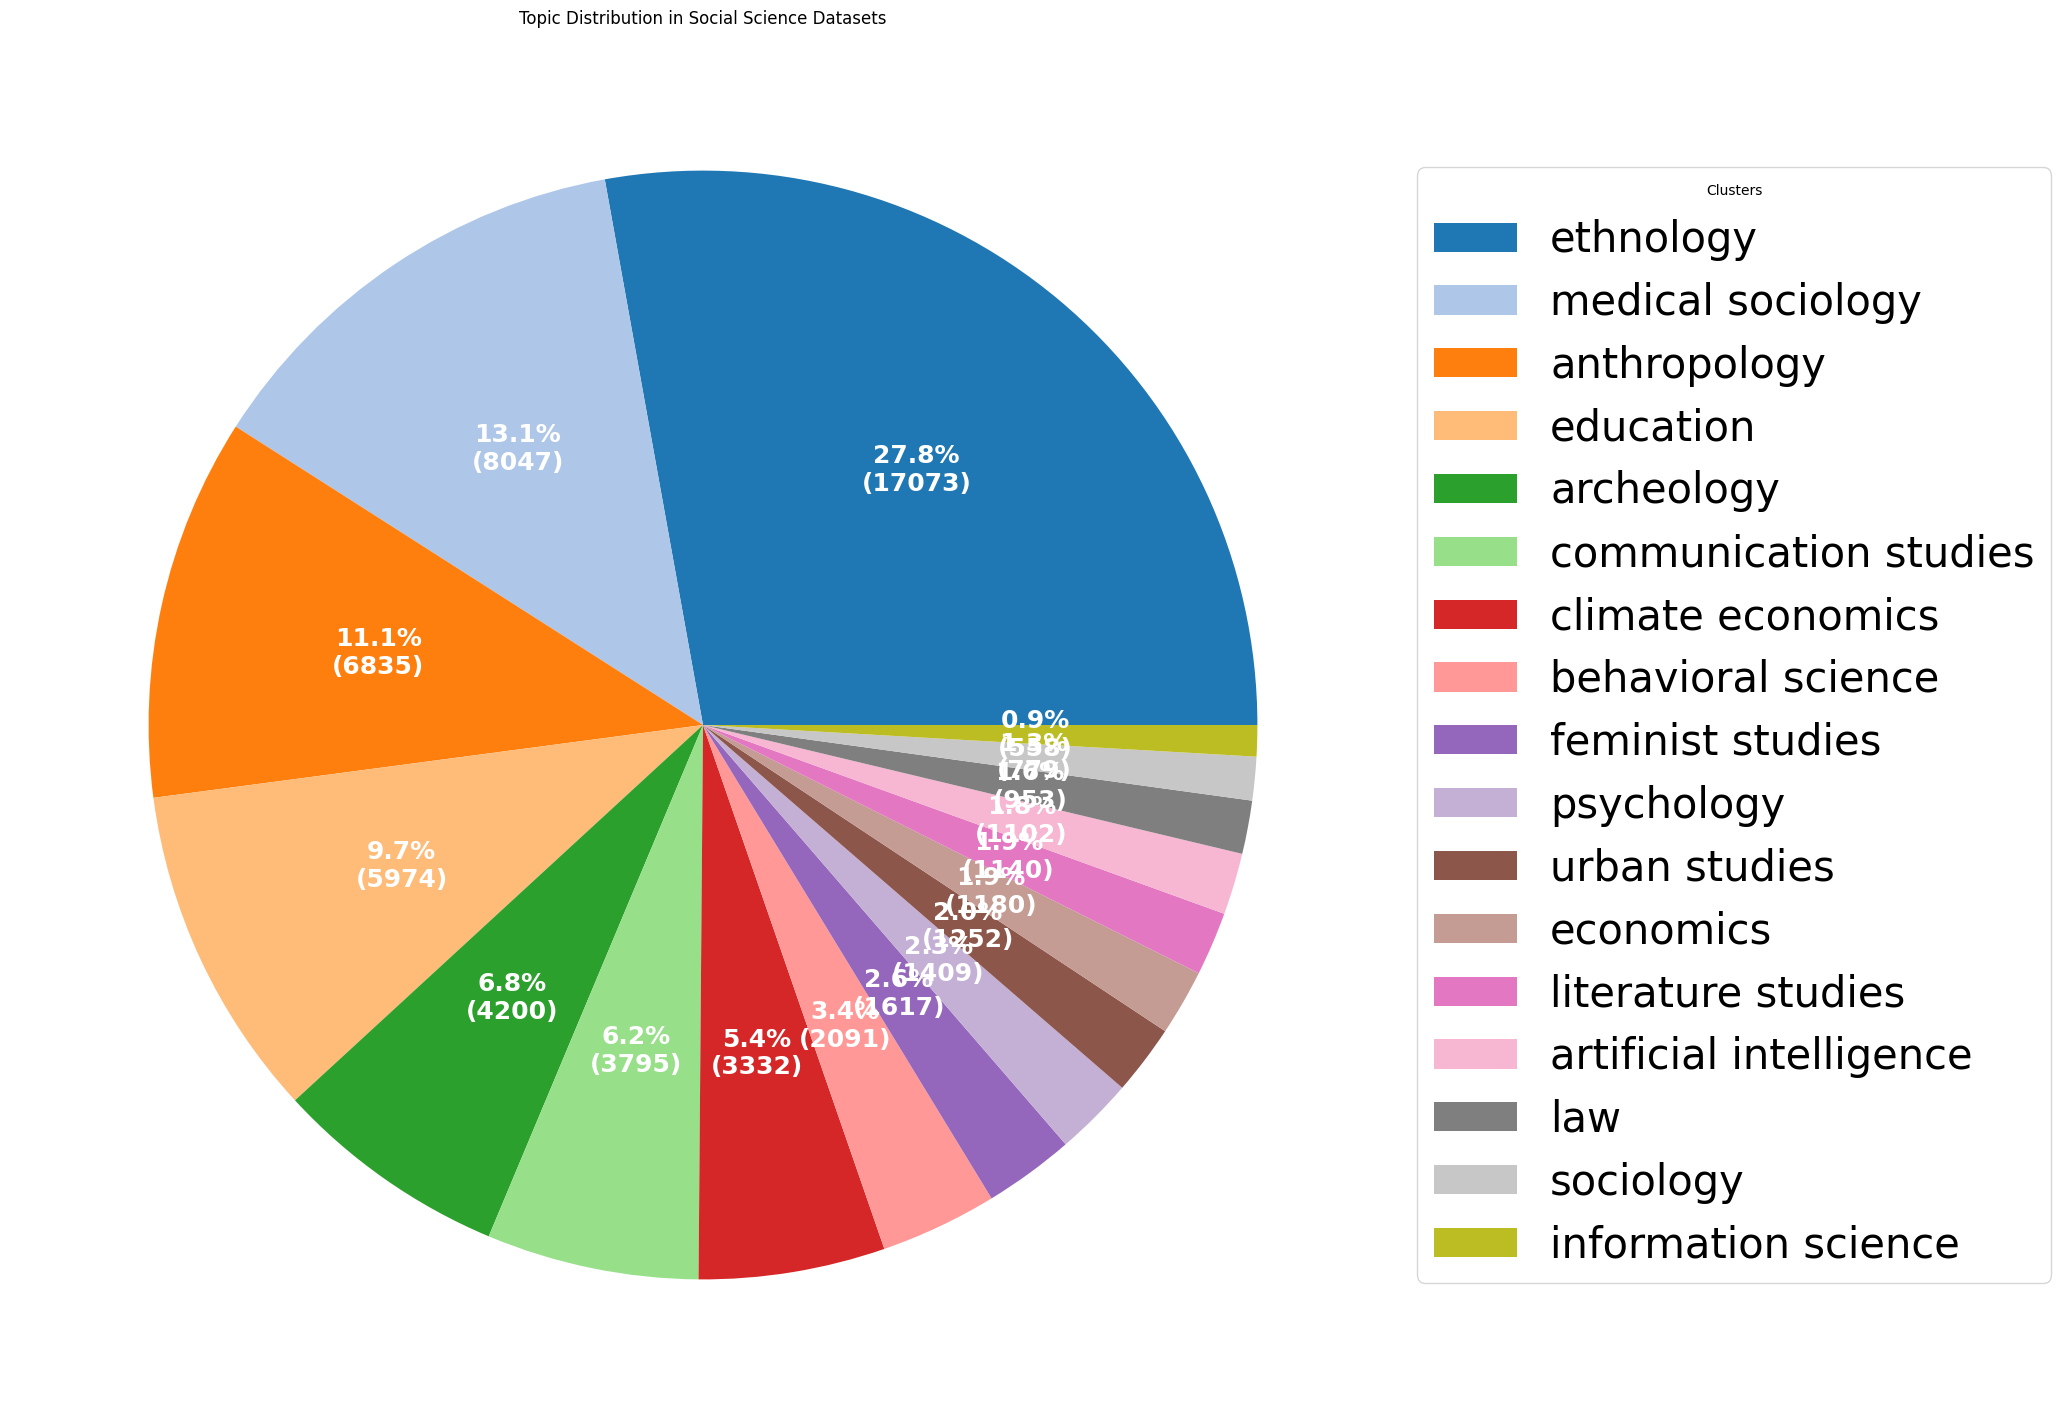

In [77]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(36, 18))
labels = data_visualise_cat['category'].to_list()
values = data_visualise_cat['count'].to_list()
total = sum(values)
wedges, _, _ = ax.pie(
values,
colors=plt.cm.tab20.colors,
    autopct=lambda pct: f"{pct:.1f}%\n({round(pct * total / 100):d})",
textprops={"color": "w", "size": 18, "weight": "bold"},
)

ax.legend(
wedges,
list(labels),
title="Clusters",
loc="center left",
bbox_to_anchor=(1, 0, 0.5, 1),
fontsize=30,

)
ax.set_title("Topic Distribution in Social Science Datasets")
plt.show()



Timestamp('1970-01-01 00:00:00.000001970')

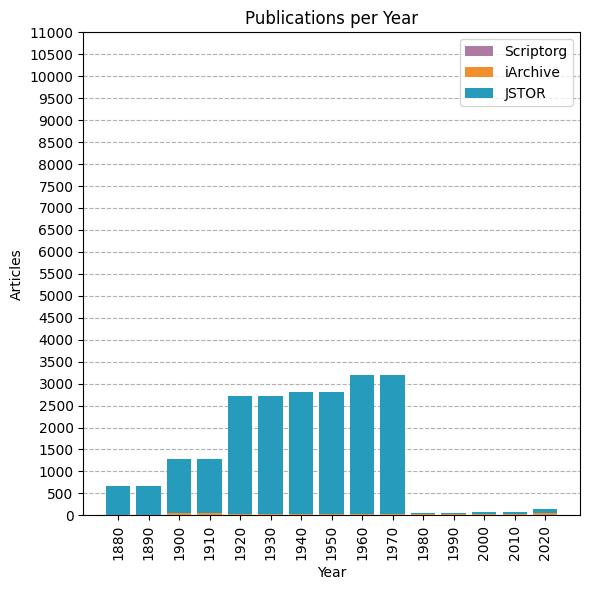

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Group by individual year (not decade)
date_scriptorg_year = df_scriptorg_cat_date.groupby(by=df_scriptorg_cat_date['year'].dt.year//10*10, dropna=False).count()
date_iarchive_year = df_iarchive_cat_year_enhanced.groupby(by=df_iarchive_cat_year_enhanced['year'].dt.year//10*10, dropna=False).count()
date_jstor_year = df_jstor_cat_date.groupby(by=df_jstor_cat_date['year'].dt.year//10*10, dropna=False).count()

# Build a common year index covering the full range across all three datasets
all_years = sorted(
    set(date_scriptorg_year.index)
    | set(date_iarchive_year.index)
    | set(date_jstor_year.index)
)
full_range = pd.Index(range(min(all_years), max(all_years) + 10, 10), name="decade")

s1 = date_scriptorg_year.reindex(full_range, fill_value=0)
s2 = date_iarchive_year.reindex(full_range, fill_value=0)
s3 = date_jstor_year.reindex(full_range, fill_value=0)

x = np.arange(len(full_range))


plt.figure(figsize=(6, 6))

datasets = [
    (s1.values.flatten(), 'Scriptorg', '#af7aa1'),
    (s2.values.flatten(), 'iArchive', '#f28e2c'),
    (s3.values.flatten(), 'JSTOR', '#269bbb'),
]

# plot per x-position, sorted descending (largest drawn first/behind, smallest last/in front)
for i in range(len(x)):
    order = sorted(datasets, key=lambda d: d[0][i], reverse=True)
    for values, label, color in order:
        plt.bar(x[i], values[i], color=color, zorder=3)

# dummy bars just for the legend, since the loop above doesn't produce one clean entry per label
for _, label, color in datasets:
    plt.bar(0, 0, width=0.1, color=color, label=label)

plt.title("Publications per Year")
plt.grid(True, axis='y', linestyle='--', zorder=0)
plt.xlabel("Year")
plt.ylabel("Articles")
plt.xticks(x, full_range, rotation=90)
plt.yticks(np.arange(0, 11001, 500))
plt.legend()
plt.tight_layout()
plt.show()